# Лабораторная работа 2. Оценка качества данных, очистка и статистический анализ

**Датасет:** `9. Sales-Data-Analysis.csv` — заказы сети кафе (Лондон, Лиссабон, Мадрид, Париж, Берлин), ноябрь–декабрь 2022 г.

**Колонки:** `Order ID` — номер заказа, `Date` — дата, `Product` — товар, `Price` — цена за единицу, `Quantity` — проданное количество, `Purchase Type` — тип покупки, `Payment Method` — способ оплаты, `Manager` — менеджер, `City` — город.

**План работы:**
1. Загрузка данных
2. Анализ качества (пропуски, границы, дубликаты, корректность категорий)
3. Чистка (с контролем изменений после каждого этапа)
4. Преобразование и добавление новых полей
5. Статистический анализ (типы данных, меры центральной тенденции, меры разброса, выбросы, частотные ряды)

## 1. Загрузка данных

In [1]:
%matplotlib inline
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

In [2]:
# Универсальная загрузка: работает и локально, и в Google Colab.
CANDIDATES = [
    '9. Sales-Data-Analysis.csv',
    '/content/9. Sales-Data-Analysis.csv',   # путь в Colab после загрузки в панель «Файлы»
]
path = next((p for p in CANDIDATES if os.path.exists(p)), None)

if path is None:
    # В Colab: откроется диалог выбора файла
    from google.colab import files
    print('Файл не найден, выберите CSV в диалоге загрузки:')
    uploaded = files.upload()
    path = next(iter(uploaded))

df_raw = pd.read_csv(path)
df = df_raw.copy()
print('Загружен файл:', path)
print('Размер таблицы:', df.shape)

Загружен файл: 9. Sales-Data-Analysis.csv
Размер таблицы: (254, 9)


In [3]:
df.head(10)

,Order ID,Date,Product,Price,Quantity,Purchase Type,Payment Method,Manager,City
0,10452,07-11-2022,Fries,3.49,573.07,Online,Gift Card,Tom Jackson,London
1,10453,07-11-2022,Beverages,2.95,745.76,Online,Gift Card,Pablo Perez,Madrid
2,10454,07-11-2022,Sides & Other,4.99,200.40,In-store,Gift Card,Joao Silva,Lisbon
3,10455,08-11-2022,Burgers,12.99,569.67,In-store,Credit Card,Walter Muller,Berlin
4,10456,08-11-2022,Chicken Sandwiches,9.95,201.01,In-store,Credit Card,Walter Muller,Berlin
5,10457,08-11-2022,Fries,3.49,573.07,In-store,Credit Card,Remy Monet,Paris
6,10459,08-11-2022,Sides & Other,4.99,200.40,In-store,Credit Card,Walter Muller,Berlin
7,10460,09-11-2022,Burgers,12.99,554.27,In-store,Credit Card,Remy Monet,Paris
8,10461,09-11-2022,Chicken Sandwiches,9.95,201.01,In-store,Credit Card,Remy Monet,Paris
9,10462,09-11-2022,Fries,3.49,573.07,In-store,Credit Card,Remy Monet,Paris


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 254 entries, 0 to 253
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order ID        254 non-null    int64  
 1   Date            254 non-null    object 
 2   Product         254 non-null    object 
 3   Price           254 non-null    float64
 4   Quantity        254 non-null    float64
 5   Purchase Type   254 non-null    object 
 6   Payment Method  254 non-null    object 
 7   Manager         254 non-null    object 
 8   City            254 non-null    object 
dtypes: float64(2), int64(1), object(6)
memory usage: 18.0+ KB


In [5]:
df.describe(include='all')

,Order ID,Date,Product,Price,Quantity,Purchase Type,Payment Method,Manager,City
count,254.00,254,254,254.00,254.00,254,254,254,254
unique,NaN,53,5,NaN,NaN,3,3,14,5
top,NaN,03-12-2022,Burgers,NaN,NaN,Online,Credit Card,Tom Jackson,London
freq,NaN,5,52,NaN,NaN,107,120,74,75
mean,"10,584.13",NaN,NaN,7.10,460.61,NaN,NaN,NaN,NaN
std,75.89,NaN,NaN,4.34,214.89,NaN,NaN,NaN,NaN
min,"10,452.00",NaN,NaN,2.95,200.40,NaN,NaN,NaN,NaN
25%,"10,520.25",NaN,NaN,3.49,201.01,NaN,NaN,NaN,NaN
50%,"10,583.50",NaN,NaN,4.99,538.88,NaN,NaN,NaN,NaN
75%,"10,649.75",NaN,NaN,9.95,677.44,NaN,NaN,NaN,NaN


## 2. Анализ качества данных

Проверяем: **пропущенные значения**, **дубликаты**, **границы значений** числовых полей и дат, **корректность категорий** в номинальных признаках.

### 2.1. Пропущенные значения

In [6]:
na = df.isna().sum()
print('Пропущенных значений по колонкам:')
print(na)
print()
print('Итого пропусков в таблице:', int(na.sum()))

Пропущенных значений по колонкам:
Order ID          0
Date              0
Product           0
Price             0
Quantity          0
Purchase Type     0
Payment Method    0
Manager           0
City              0
dtype: int64

Итого пропусков в таблице: 0


**Вывод:** пропусков в данных нет — все 254 строки заполнены по всем 9 колонкам.

### 2.2. Дубликаты

In [7]:
print('Полных дубликатов строк:', int(df.duplicated().sum()))
print('Повторяющихся Order ID:', int(df['Order ID'].duplicated().sum()))

dup_id = df[df['Order ID'].duplicated(keep=False)]
if not dup_id.empty:
    display(dup_id.sort_values('Order ID'))
else:
    print('Каждый Order ID встречается ровно один раз — дубликатов заказов нет.')

Полных дубликатов строк: 0
Повторяющихся Order ID: 0
Каждый Order ID встречается ровно один раз — дубликатов заказов нет.


**Вывод:** полных дубликатов строк и повторяющихся номеров заказов нет. (Проверка повторяется после чистки, т.к. «дубликаты из-за лишних пробелов» могли бы появиться/исчезнуть при нормализации текста.)

### 2.3. Границы значений числовых полей

In [8]:
num_cols = ['Price', 'Quantity']
print('Диапазоны числовых полей:')
display(df[num_cols].agg(['min', 'max', 'mean']).T)

print('Уникальные значения Price:', sorted(df['Price'].unique()))
print()
print('Признак: у каждого товара должна быть одна справочная цена.')
print('Фактические цены по товарам (число строк с каждой ценой):')
display(df.groupby('Product')['Price'].value_counts().to_frame('n'))

Диапазоны числовых полей:


,min,max,mean
Price,2.95,29.05,7.10
Quantity,200.40,754.43,460.61


Уникальные значения Price: [np.float64(2.95), np.float64(3.49), np.float64(4.99), np.float64(9.95), np.float64(12.99), np.float64(25.5), np.float64(29.05)]

Признак: у каждого товара должна быть одна справочная цена.
Фактические цены по товарам (число строк с каждой ценой):


n
Product            Price    
Beverages          2.95   50
Burgers            12.99  52
Chicken Sandwiches 9.95   51
                   29.05   1
Fries              3.49   50
                   25.50   1
Sides & Other      4.99   49

**Проблема найдена:** у каждого товара ровно одна «каталожная» цена, кроме двух строк-выбросов:
- `Fries` с ценой **25.5** (каталожная цена картофеля — 3.49),
- `Chicken Sandwiches` с ценой **29.05** (каталожная цена — 9.95).

Это опечатки/ошибки ввода: цены не соответствуют ассортименту (остальные цены лежат в диапазоне 2.95–12.99).

`Quantity` принимает **дробные** значения (например, 573.07 шт.) — количество единиц товара должно быть целым, это аномалия формата, исправим на этапе преобразований.

### 2.4. Корректность дат

In [9]:
print('Тип колонки Date до преобразования:', df['Date'].dtype)
print('Примеры значений:', df['Date'].head(3).tolist())

parsed = pd.to_datetime(df['Date'], dayfirst=True, errors='coerce')
print('Невалидных дат (не парсятся):', int(parsed.isna().sum()))
print('Диапазон дат:', parsed.min().date(), '—', parsed.max().date())

Тип колонки Date до преобразования: object
Примеры значений: ['07-11-2022', '07-11-2022', '07-11-2022']
Невалидных дат (не парсятся): 0
Диапазон дат: 2022-11-07 — 2022-12-29


**Вывод:** все даты записаны в едином формате `ДД-ММ-ГГГГ` и валидны, диапазон — ноябрь–декабрь 2022 г. Проблем нет, но колонка хранится как **строка** (`object`), а не как дата — нужен каст в `datetime64`.

### 2.5. Корректность категорий

In [10]:
cat_cols = ['Product', 'Purchase Type', 'Payment Method', 'Manager', 'City']
for c in cat_cols:
    print(f'--- {c}: {df[c].nunique()} уникальных значений ---')
    print(df[c].value_counts(dropna=False).to_string())
    print()

--- Product: 5 уникальных значений ---
Product
Burgers               52
Chicken Sandwiches    52
Fries                 51
Beverages             50
Sides & Other         49

--- Purchase Type: 3 уникальных значений ---
Purchase Type
Online         107
In-store        86
Drive-thru      61

--- Payment Method: 3 уникальных значений ---
Payment Method
Credit Card    120
Cash            76
Gift Card       58

--- Manager: 14 уникальных значений ---
Manager
Tom Jackson           74
Joao Silva            70
Pablo Perez           36
Walter Muller         30
Remy Monet            24
       Pablo Perez     7
Joao    Silva          5
       Remy Monet      2
Tom      Jackson       1
Remy    Monet          1
Remy     Monet         1
Pablo   Perez          1
Pablo  Perez           1
Pablo    Perez         1

--- City: 5 уникальных значений ---
City
London    75
Lisbon    75
Madrid    46
Berlin    30
Paris     28



**Проблема найдена.** Реальных категорий в данных меньше, чем уникальных значений:
- `Manager`: **14 вариантов вместо 5** — лишние пробелы внутри имён и по краям (`"Joao    Silva"`, `"       Pablo Perez"` и т.п.);
- `Purchase Type`: 3 реальные категории (`Online`, `In-store`, `Drive-thru`), но у всех хвостовой пробел;
- `Payment Method`: 3 реальные категории (`Cash`, `Credit Card`, `Gift Card`), но у всех ведущий пробел;
- `Product` (5 значений) и `City` (5 значений) — корректны.

### 2.6. Сводка проблем качества

| # | Проверка | Результат | Что делаем |
|---|----------|-----------|------------|
| 1 | Пропущенные значения | **Не найдены** | Контрольная проверка после чистки |
| 2 | Дубликаты строк / Order ID | **Не найдены** | Повторная проверка после нормализации |
| 3 | Границы `Price` | **2 аномалии**: 25.5 и 29.05 вне каталожных цен | Восстановить каталожную цену товара |
| 4 | Формат `Quantity` | Дробные значения вместо целых | Округлить и привести к `int` |
| 5 | Тип `Date` | Строка вместо даты | Каст в `datetime64` |
| 6 | Категории `Manager` | 14 «категорий» из-за пробелов | Нормализовать пробелы |
| 7 | Категории `Purchase Type`, `Payment Method` | Ведущие/хвостовые пробелы | Нормализовать пробелы |

## 3. Чистка данных

Каждый этап: фиксируем состояние «до» → выполняем преобразование → показываем «после».

### 3.1. Нормализация пробелов в текстовых колонках

In [11]:
snapshot = df.copy()
text_cols = df.select_dtypes(include='object').columns

for c in text_cols:
    df[c] = (df[c].astype(str)
                   .str.strip()                              # пробелы по краям
                   .str.replace(r'\s+', ' ', regex=True))    # двойные пробелы внутри

print('Менеджеры ДО :', snapshot['Manager'].nunique(), 'вариантов')
print('Менеджеры ПОСЛЕ:', df['Manager'].nunique(), 'вариантов')
print()
print('Категории после нормализации:')
for c in ['Manager', 'Purchase Type', 'Payment Method']:
    print(f'--- {c} ---')
    print(df[c].value_counts().to_string())
print()
n_changed = int((snapshot[text_cols] != df[text_cols]).any(axis=1).sum())
print(f'Строк, в которых изменился текст: {n_changed} из {len(df)}')

Менеджеры ДО : 14 вариантов
Менеджеры ПОСЛЕ: 5 вариантов

Категории после нормализации:
--- Manager ---
Manager
Tom Jackson      75
Joao Silva       75
Pablo Perez      46
Walter Muller    30
Remy Monet       28
--- Purchase Type ---
Purchase Type
Online        107
In-store       86
Drive-thru     61
--- Payment Method ---
Payment Method
Credit Card    120
Cash            76
Gift Card       58

Строк, в которых изменился текст: 254 из 254


**Изменение:** вместо 14 «разных менеджеров» осталось 5 реальных сотрудников; категории `Purchase Type` и `Payment Method` очищены от пробелов. Сами значения (люди, товары, города) не менялись — только представление текста.

### 3.2. Исправление аномальных цен по каталожной цене товара

In [12]:
catalog = df.groupby('Product')['Price'].agg(lambda s: s.mode().iloc[0])
print('Каталожные цены (мода по каждому товару):')
print(catalog.to_string())
print()

mask = df['Price'] != df['Product'].map(catalog)
fixed = df.loc[mask, ['Order ID', 'Product', 'Price']].copy()
fixed['Price до исправления'] = fixed['Price']
df.loc[mask, 'Price'] = df.loc[mask, 'Product'].map(catalog)
fixed['Price после исправления'] = df.loc[mask, 'Price'].values

print(f'Найдено и исправлено строк с некаталожной ценой: {int(mask.sum())}')
display(fixed.reset_index(drop=True))
print()
print('Уникальные цены после исправления:', sorted(df['Price'].unique()))

Каталожные цены (мода по каждому товару):
Product
Beverages             2.95
Burgers              12.99
Chicken Sandwiches    9.95
Fries                 3.49
Sides & Other         4.99

Найдено и исправлено строк с некаталожной ценой: 2


,Order ID,Product,Price,Price до исправления,Price после исправления
0,10482,Fries,25.50,25.50,3.49
1,10486,Chicken Sandwiches,29.05,29.05,9.95



Уникальные цены после исправления: [np.float64(2.95), np.float64(3.49), np.float64(4.99), np.float64(9.95), np.float64(12.99)]


**Изменение:** цена — справочная величина, зависящая только от товара, поэтому аномальные значения (25.5 → 3.49 для картофеля, 29.05 → 9.95 для сэндвичей) восстановлены по каталожной цене. Теперь у каждого товара ровно одна цена.

### 3.3. Приведение дат к типу datetime

In [13]:
print('ДО :', df['Date'].dtype, '| пример:', df['Date'].iloc[0])
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
print('ПОСЛЕ:', df['Date'].dtype, '| пример:', df['Date'].iloc[0].date())
print('Пропусков после парсинга (NaT):', int(df['Date'].isna().sum()))
print('Диапазон дат:', df['Date'].min().date(), '—', df['Date'].max().date())

ДО : object | пример: 07-11-2022
ПОСЛЕ: datetime64[ns] | пример: 2022-11-07
Пропусков после парсинга (NaT): 0
Диапазон дат: 2022-11-07 — 2022-12-29


**Измерение:** `Date` теперь настоящий `datetime64` — с датами можно считать (сортировка, разности, извлечение месяца и дня недели).

### 3.4. Контрольная проверка дубликатов и пропусков

In [14]:
print('Дубликатов строк:', int(df.duplicated().sum()))
print('Повторяющихся Order ID:', int(df['Order ID'].duplicated().sum()))
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Строк было: {before}, стало: {len(df)} (удалено {before - len(df)})')
print()
print('Пропусков после чистки:', int(df.isna().sum().sum()))

Дубликатов строк: 0
Повторяющихся Order ID: 0
Строк было: 254, стало: 254 (удалено 0)

Пропусков после чистки: 0


**Изменение:** дубликатов и пропусков нет, размер таблицы не изменился. Чистка завершилась без потери строк — исправлялись только значения внутри ячеек.

## 4. Преобразование и добавление новых полей

### 4.1. `Quantity` → целое число

In [15]:
print('ДО :', df['Quantity'].dtype, '| примеры:', df['Quantity'].head(3).tolist())
df['Quantity'] = df['Quantity'].round().astype(int)
print('ПОСЛЕ:', df['Quantity'].dtype, '| примеры:', df['Quantity'].head(3).tolist())
print('Диапазон Quantity:', df['Quantity'].min(), '—', df['Quantity'].max())

ДО : float64 | примеры: [573.07, 745.76, 200.4]
ПОСЛЕ: int64 | примеры: [573, 746, 200]
Диапазон Quantity: 200 — 754


Количество единиц товара — целое по смыслу; дробная часть (например, 573.07 шт.) — артефакт источника, устраняем округлением.

### 4.2. Новые поля: выручка и календарные признаки

In [16]:
df['Revenue'] = df['Price'] * df['Quantity']          # выручка заказа
df['Year'] = df['Date'].dt.year                        # год
df['Month'] = df['Date'].dt.month                      # номер месяца
df['MonthName'] = df['Date'].dt.strftime('%B')         # название месяца
df['Day'] = df['Date'].dt.day                          # день месяца
df['Weekday'] = df['Date'].dt.day_name()               # день недели

print('Новые колонки добавлены. Итоговая структура:')
df.info()

Новые колонки добавлены. Итоговая структура:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 254 entries, 0 to 253
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order ID        254 non-null    int64         
 1   Date            254 non-null    datetime64[ns]
 2   Product         254 non-null    object        
 3   Price           254 non-null    float64       
 4   Quantity        254 non-null    int64         
 5   Purchase Type   254 non-null    object        
 6   Payment Method  254 non-null    object        
 7   Manager         254 non-null    object        
 8   City            254 non-null    object        
 9   Revenue         254 non-null    float64       
 10  Year            254 non-null    int32         
 11  Month           254 non-null    int32         
 12  MonthName       254 non-null    object        
 13  Day             254 non-null    int32         
 14  Weekday      

In [17]:
df.head(8)

,Order ID,Date,Product,Price,Quantity,Purchase Type,Payment Method,Manager,City,Revenue,Year,Month,MonthName,Day,Weekday
0,10452,2022-11-07,Fries,3.49,573,Online,Gift Card,Tom Jackson,London,"1,999.77",2022,11,November,7,Monday
1,10453,2022-11-07,Beverages,2.95,746,Online,Gift Card,Pablo Perez,Madrid,"2,200.70",2022,11,November,7,Monday
2,10454,2022-11-07,Sides & Other,4.99,200,In-store,Gift Card,Joao Silva,Lisbon,998.00,2022,11,November,7,Monday
3,10455,2022-11-08,Burgers,12.99,570,In-store,Credit Card,Walter Muller,Berlin,"7,404.30",2022,11,November,8,Tuesday
4,10456,2022-11-08,Chicken Sandwiches,9.95,201,In-store,Credit Card,Walter Muller,Berlin,"1,999.95",2022,11,November,8,Tuesday
5,10457,2022-11-08,Fries,3.49,573,In-store,Credit Card,Remy Monet,Paris,"1,999.77",2022,11,November,8,Tuesday
6,10459,2022-11-08,Sides & Other,4.99,200,In-store,Credit Card,Walter Muller,Berlin,998.00,2022,11,November,8,Tuesday
7,10460,2022-11-09,Burgers,12.99,554,In-store,Credit Card,Remy Monet,Paris,"7,196.46",2022,11,November,9,Wednesday


## 5. Статистический анализ

### 5.1. Типы данных после чистки и преобразований

In [18]:
display(df.dtypes.to_frame('Тип данных'))

,Тип данных
Order ID,int64
Date,datetime64[ns]
Product,object
Price,float64
Quantity,int64
Purchase Type,object
Payment Method,object
Manager,object
City,object
Revenue,float64


Количественные (`Price`, `Quantity`, `Revenue` и календарные) — числовые типы; дата — `datetime64`; номинальные признаки — `object` (категориальные строки).

### 5.2. Меры центральной тенденции

In [19]:
num_cols = ['Price', 'Quantity', 'Revenue']
central = pd.DataFrame({
    'Среднее (mean)': df[num_cols].mean(),
    'Медиана (median)': df[num_cols].median(),
    'Мода (mode)': [df[c].mode().iloc[0] for c in num_cols],
})
display(central)

print('Мода номинальных признаков (наиболее частая категория):')
for c in ['Product', 'City', 'Manager', 'Payment Method', 'Purchase Type', 'Weekday']:
    print(f'  {c:15s} -> {df[c].mode().iloc[0]}')

,Среднее (mean),Медиана (median),Мода (mode)
Price,6.94,4.99,9.95
Quantity,460.48,539.00,200.00
Revenue,"2,959.03","2,000.10",998.00


Мода номинальных признаков (наиболее частая категория):
  Product         -> Burgers
  City            -> Lisbon
  Manager         -> Joao Silva
  Payment Method  -> Credit Card
  Purchase Type   -> Online
  Weekday         -> Wednesday


Для `Price` все три меры близки (цены почти равномерно распределены по 5 товарам). Для `Quantity` и `Revenue` медиана немного меньше среднего — распределение имеет лёгкую правостороннюю асимметрию из-за крупных заказов.

### 5.3. Меры разброса

In [20]:
disp = pd.DataFrame({
    'Минимум (min)': df[num_cols].min(),
    'Максимум (max)': df[num_cols].max(),
    'Размах (range)': df[num_cols].max() - df[num_cols].min(),
    'Дисперсия (var)': df[num_cols].var(),
    'Ст. отклонение (std)': df[num_cols].std(),
    'Q1 (25%)': df[num_cols].quantile(.25),
    'Q3 (75%)': df[num_cols].quantile(.75),
    'IQR': df[num_cols].quantile(.75) - df[num_cols].quantile(.25),
})
disp['Коэф. вариации, %'] = df[num_cols].std() / df[num_cols].mean() * 100
display(disp)

,Минимум (min),Максимум (max),Размах (range),Дисперсия (var),Ст. отклонение (std),Q1 (25%),Q3 (75%),IQR,"Коэф. вариации, %"
Price,2.95,12.99,10.04,15.67,3.96,3.49,9.95,6.46,57.03
Quantity,200.00,754.00,554.00,"46,216.16",214.98,201.00,677.00,476.00,46.69
Revenue,998.00,"9,794.46","8,796.46","5,155,169.21","2,270.50","1,999.95","2,400.33",400.38,76.73


Цены слабо рассеяны (CV ≈ 60% при всего 5 фиксированных значениях, разброс задаётся ассортиментом). `Quantity` и `Revenue` варьируют сильно (CV > 30%) — заказы заметно различаются по объёму продаж.

### 5.4. Выбросы (метод IQR и z-оценка)

In [21]:
def iqr_bounds(s):
    q1, q3 = s.quantile(.25), s.quantile(.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

print(f"{'Колонка':10s} {'Границы IQR':>22s} {'Выбросов (IQR)':>15s} {'Выбросов (|z|>3)':>17s}")
for c in num_cols:
    lo, hi = iqr_bounds(df[c])
    out_iqr = df[(df[c] < lo) | (df[c] > hi)]
    z = (df[c] - df[c].mean()) / df[c].std()
    out_z = df[z.abs() > 3]
    print(f'{c:10s} {f"[{lo:8.2f}; {hi:8.2f}]":>22s} {len(out_iqr):15d} {len(out_z):17d}')

print()
z = (df['Revenue'] - df['Revenue'].mean()) / df['Revenue'].std()
print('Единственная строка с |z| > 3 по Revenue:')
display(df.loc[z.abs() > 3, ['Order ID', 'Date', 'Product', 'Quantity', 'Revenue']])

print()
print('Проверка внутри групп (границы IQR отдельно по каждому товару):')
rows = []
for p, g in df.groupby('Product'):
    q1, q3 = g['Revenue'].quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = int(((g['Revenue'] < lo) | (g['Revenue'] > hi)).sum())
    rows.append({'Product': p, 'n': len(g), 'Q1': q1, 'Q3': q3, 'IQR': iqr,
                 'Границы': f'[{lo:,.0f}; {hi:,.0f}]', 'Выбросов': n})
display(pd.DataFrame(rows))

Колонка               Границы IQR  Выбросов (IQR)  Выбросов (|z|>3)
Price        [   -6.20;    19.64]               0                 0
Quantity     [ -513.00;  1391.00]               0                 0
Revenue      [ 1399.38;  3000.89]             102                 1

Единственная строка с |z| > 3 по Revenue:


,Order ID,Date,Product,Quantity,Revenue
250,10710,2022-12-29,Burgers,754,"9,794.46"



Проверка внутри групп (границы IQR отдельно по каждому товару):


,Product,n,Q1,Q3,IQR,Границы,Выбросов
0,Beverages,50,"2,000.10","2,200.70",200.60,"[1,699; 2,502]",0
1,Burgers,52,"6,598.92","7,599.15","1,000.23","[5,099; 9,099]",2
2,Chicken Sandwiches,52,"1,999.95","2,198.95",199.00,"[1,701; 2,497]",5
3,Fries,51,"2,198.70","2,198.70",0.00,"[2,199; 2,199]",16
4,Sides & Other,49,998.00,998.00,0.00,[998; 998],0


Формальные методы дают разные результаты по разным признакам, и это важный методологический момент:

- `Price` и `Quantity`: **выбросов нет** — оба метода согласованы;
- `Revenue`: глобальный IQR помечает 102 из 254 строк (~40%). Это **не аномалии**: распределение выручки мультимодально — это смесь пяти ценовых уровней и кластеров количества, а метод IQR корректен для унимодальных распределений и на смесях даёт массовые ложные срабатывания. Групповая проверка внутри каждого товара показывает то же следствие дискретности данных: у `Fries` и `Sides & Other` IQR = 0 (более половины значений совпадают), границы вырождаются в точку;
- правило |z| > 3 находит единственный заказ № 10710 (Burgers, 754 шт., выручка 9 794.46) — это **правдоподобный крупный заказ**, а не ошибка: цена каталожная, количество в допустимых пределах.

**Общий вывод:** после чистки физически некорректных значений в данных не осталось. Показательно, что истинные ошибки ввода (цены 25.5 и 29.05) формальные fence-методы нашли бы не полностью (25.5 не выходит за границу 1.5·IQR) — обе аномалии были выявлены бизнес-правилом «у товара одна каталожная цена» на этапе 2.

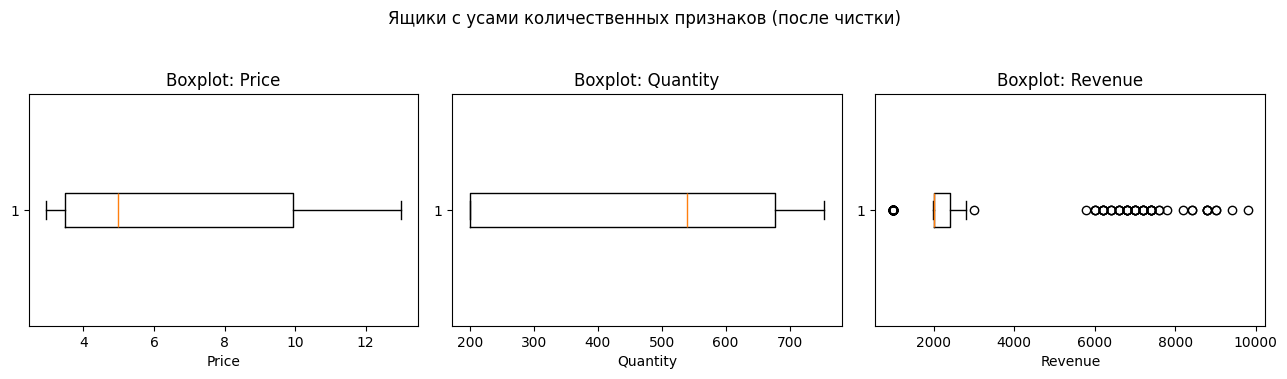

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, c in zip(axes, num_cols):
    ax.boxplot(df[c], vert=False)
    ax.set_title(f'Boxplot: {c}')
    ax.set_xlabel(c)
fig.suptitle('Ящики с усами количественных признаков (после чистки)', y=1.04)
plt.tight_layout()
plt.show()

### 5.5. Частотные ряды

**Категориальные признаки — дискретные частотные ряды:**

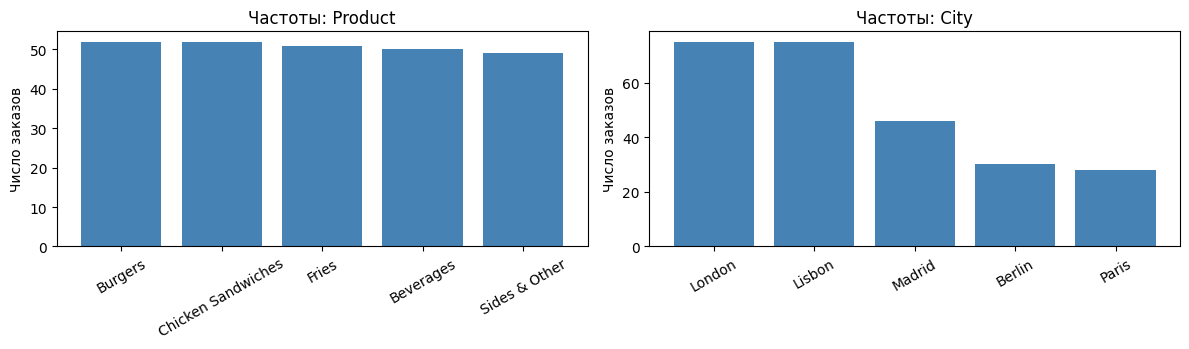

--- Product ---
                    Частота  Отн. частота
Product                                  
Burgers                  52          0.20
Chicken Sandwiches       52          0.20
Fries                    51          0.20
Beverages                50          0.20
Sides & Other            49          0.19

--- City ---
        Частота  Отн. частота
City                         
London       75          0.29
Lisbon       75          0.29
Madrid       46          0.18
Berlin       30          0.12
Paris        28          0.11

--- Manager ---
               Частота  Отн. частота
Manager                             
Tom Jackson         75          0.29
Joao Silva          75          0.29
Pablo Perez         46          0.18
Walter Muller       30          0.12
Remy Monet          28          0.11

--- Payment Method ---
                Частота  Отн. частота
Payment Method                       
Credit Card         120          0.47
Cash                 76          0.30
Gift Card     

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, c in zip(axes, ['Product', 'City']):
    vc = df[c].value_counts()
    ax.bar(vc.index, vc.values, color='steelblue')
    ax.set_title(f'Частоты: {c}')
    ax.set_ylabel('Число заказов')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

for c in ['Product', 'City', 'Manager', 'Payment Method', 'Purchase Type']:
    freq = pd.DataFrame({
        'Частота': df[c].value_counts(),
        'Отн. частота': df[c].value_counts(normalize=True).round(3),
    })
    print(f'--- {c} ---')
    print(freq.to_string())
    print()

**Количественные признаки — интервальные частотные ряды:**

--- Интервальный ряд: Quantity ---
                    Частота  Отн. частота
Quantity                                 
(199.446, 292.333]      100          0.39
(292.333, 384.667]        1          0.00
(384.667, 477.0]          9          0.04
(477.0, 569.333]         23          0.09
(569.333, 661.667]       56          0.22
(661.667, 754.0]         65          0.26

--- Интервальный ряд: Revenue ---
                      Частота  Отн. частота
Revenue                                    
(989.204, 2464.077]       197          0.78
(2464.077, 3930.153]        5          0.02
(3930.153, 5396.23]         0          0.00
(5396.23, 6862.307]        22          0.09
(6862.307, 8328.383]       20          0.08
(8328.383, 9794.46]        10          0.04



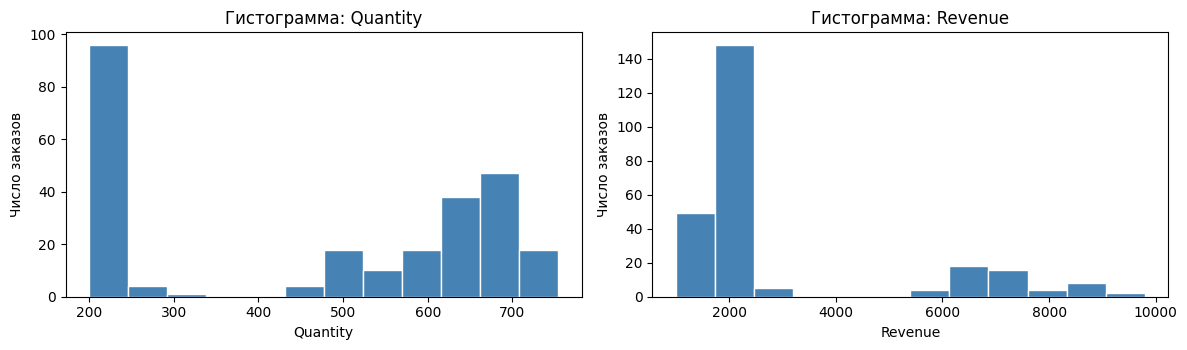

In [24]:
for c in ['Quantity', 'Revenue']:
    bins = pd.cut(df[c], bins=6)
    freq = pd.DataFrame({
        'Частота': bins.value_counts().sort_index(),
        'Отн. частота': bins.value_counts(normalize=True).sort_index().round(3),
    })
    freq.index = freq.index.astype(str)
    print(f'--- Интервальный ряд: {c} ---')
    print(freq.to_string())
    print()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, c in zip(axes, ['Quantity', 'Revenue']):
    ax.hist(df[c], bins=12, color='steelblue', edgecolor='white')
    ax.set_title(f'Гистограмма: {c}')
    ax.set_xlabel(c)
    ax.set_ylabel('Число заказов')
plt.tight_layout()
plt.show()

## Выводы

1. **Качество данных.** Пропусков и дубликатов в датасете нет; найденные проблемы — ошибки представления и ввода: лишние пробелы в категориях (14 фиктивных «менеджеров» вместо 5), две аномальные цены (25.5 и 29.05), дробный `Quantity`, дата-строка вместо типа `datetime`.
2. **Чистка.** Все проблемы устранены: текст нормализован, цены восстановлены по каталожной цене товара, `Date` приведена к `datetime64`, `Quantity` — к `int`. Потери строк — 0 (исправлялись значения, а не записи).
3. **Новые поля.** Добавлены выручка заказа `Revenue = Price × Quantity` и календарные признаки (год, месяц, день, день недели).
4. **Статистика.** Данные описаны мерами центральной тенденции (среднее/медиана/мода), разброса (размах, дисперсия, стандартное отклонение, IQR, коэффициент вариации), формально проверены на выбросы (IQR, z-оценка) и представлены частотными рядами — дискретными для категориальных и интервальными для количественных признаков.